## US Visa Prediction Project

Life cycle of machine learning project
- Understanding the problem statement
- Data Collection
- Exploratory data analysis
- Data Cleaning
- Data Pre-processing 
- model Training
- choose best model

## About

The Immigration and Nationality Act(INA) of the US permits foreign workers to come to the United states to work on either a temporary or permanent basis. the act also protects US workers against adverse impacts on working place and maintain requirements when they hire foreign workers to fill workforce shortages. the immigration programs are administered by the Office of foreign Labor Certification (OFLC).

 1.Problem statement
 - OFLC gives job certification applications for employers seeking to bring foreign workers into the United states and grants certifications
 - As in last year the count of employess were huge so OFLC needs Machine
 learning models to shortlist visa applicats based on their previous data. in this project we are going to use the data given to build a classification model:
 - This model is to check if Visa get approved or not based on the given dataset.
 - This can be used to recommend a suitable profile for the applicants for whom the visa should be certified or denied based on the certain criteria which influences the decision.

 2. Data Collection.
 - The dataset is part of Office of foreign labor certifications (OFLC) the data consists of 25480 Rows and 12 Columns
 https://www.kaggle.com/datasets/moro23/easyvisa-dataset


2.1 Import data and required packages importing pandas, Numpy, matplotlib, seaborn and warning library

In [1]:
print("hello")


hello


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings

warnings.filterwarnings("ignore")

%matplotlib inline

In [4]:
df = pd.read_csv(r"EasyVisa.csv")

In [5]:
df.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


In [6]:
df.shape

(25480, 12)

In [7]:
df.describe()

,no_of_employees,yr_of_estab,prevailing_wage
count,25480.000000,25480.000000,25480.000000
mean,5667.043210,1979.409929,74455.814592
std,22877.928848,42.366929,52815.942327
min,-26.000000,1800.000000,2.136700
25%,1022.000000,1976.000000,34015.480000
50%,2109.000000,1997.000000,70308.210000
75%,3504.000000,2005.000000,107735.512500
max,602069.000000,2016.000000,319210.270000


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   case_id                25480 non-null  object 
 1   continent              25480 non-null  object 
 2   education_of_employee  25480 non-null  object 
 3   has_job_experience     25480 non-null  object 
 4   requires_job_training  25480 non-null  object 
 5   no_of_employees        25480 non-null  int64  
 6   yr_of_estab            25480 non-null  int64  
 7   region_of_employment   25480 non-null  object 
 8   prevailing_wage        25480 non-null  float64
 9   unit_of_wage           25480 non-null  object 
 10  full_time_position     25480 non-null  object 
 11  case_status            25480 non-null  object 
dtypes: float64(1), int64(2), object(9)
memory usage: 2.3+ MB


## Exploring data

In [9]:
# define numerical and categorical coumns
numeric_features = [feature for feature in df.columns if df[feature].dtype != 'O']
categorical_features = [feature for feature in df.columns if df[feature].dtype == 'O']

# print columns
print('We have {} numerical features : {}'.format(len(numeric_features),numeric_features))
print('We have {} categorical features : {}'.format(len(categorical_features), categorical_features))

We have 3 numerical features : ['no_of_employees', 'yr_of_estab', 'prevailing_wage']
We have 9 categorical features : ['case_id', 'continent', 'education_of_employee', 'has_job_experience', 'requires_job_training', 'region_of_employment', 'unit_of_wage', 'full_time_position', 'case_status']


In [10]:
# Proportion of count data on categorical columns
for col in categorical_features:
    print(df[col].value_counts(normalize=True)*100)
    print('------------------------------')

case_id
EZYV01       0.003925
EZYV16995    0.003925
EZYV16993    0.003925
EZYV16992    0.003925
EZYV16991    0.003925
               ...   
EZYV8492     0.003925
EZYV8491     0.003925
EZYV8490     0.003925
EZYV8489     0.003925
EZYV25480    0.003925
Name: proportion, Length: 25480, dtype: float64
------------------------------
continent
Asia             66.173469
Europe           14.646782
North America    12.919937
South America     3.343799
Africa            2.162480
Oceania           0.753532
Name: proportion, dtype: float64
------------------------------
education_of_employee
Bachelor's     40.164835
Master's       37.810047
High School    13.422292
Doctorate       8.602826
Name: proportion, dtype: float64
------------------------------
has_job_experience
Y    58.092622
N    41.907378
Name: proportion, dtype: float64
------------------------------
requires_job_training
N    88.402669
Y    11.597331
Name: proportion, dtype: float64
------------------------------
region_of_employment

## Insights

- case_id have unique values for each column which can be dropped as it , here there is no importance
- continent column is highly biased towards asia. hence we can combine other categories to form a single category.
- unit_of_wages seems to be an important column as most of them are yearly contracts.



## Univariate Analysis 
- The term univariate analysis refers to the analysis of one variable prefix "uni" means "one". the purpose of univariate analysis is to understand the distribution of values for a single variable. Other Type of analysis are:
- Bivariate Analysis: The analysis of two variables
- Multivariate Analysis: The analysis of two or more variables

## Numerical Features

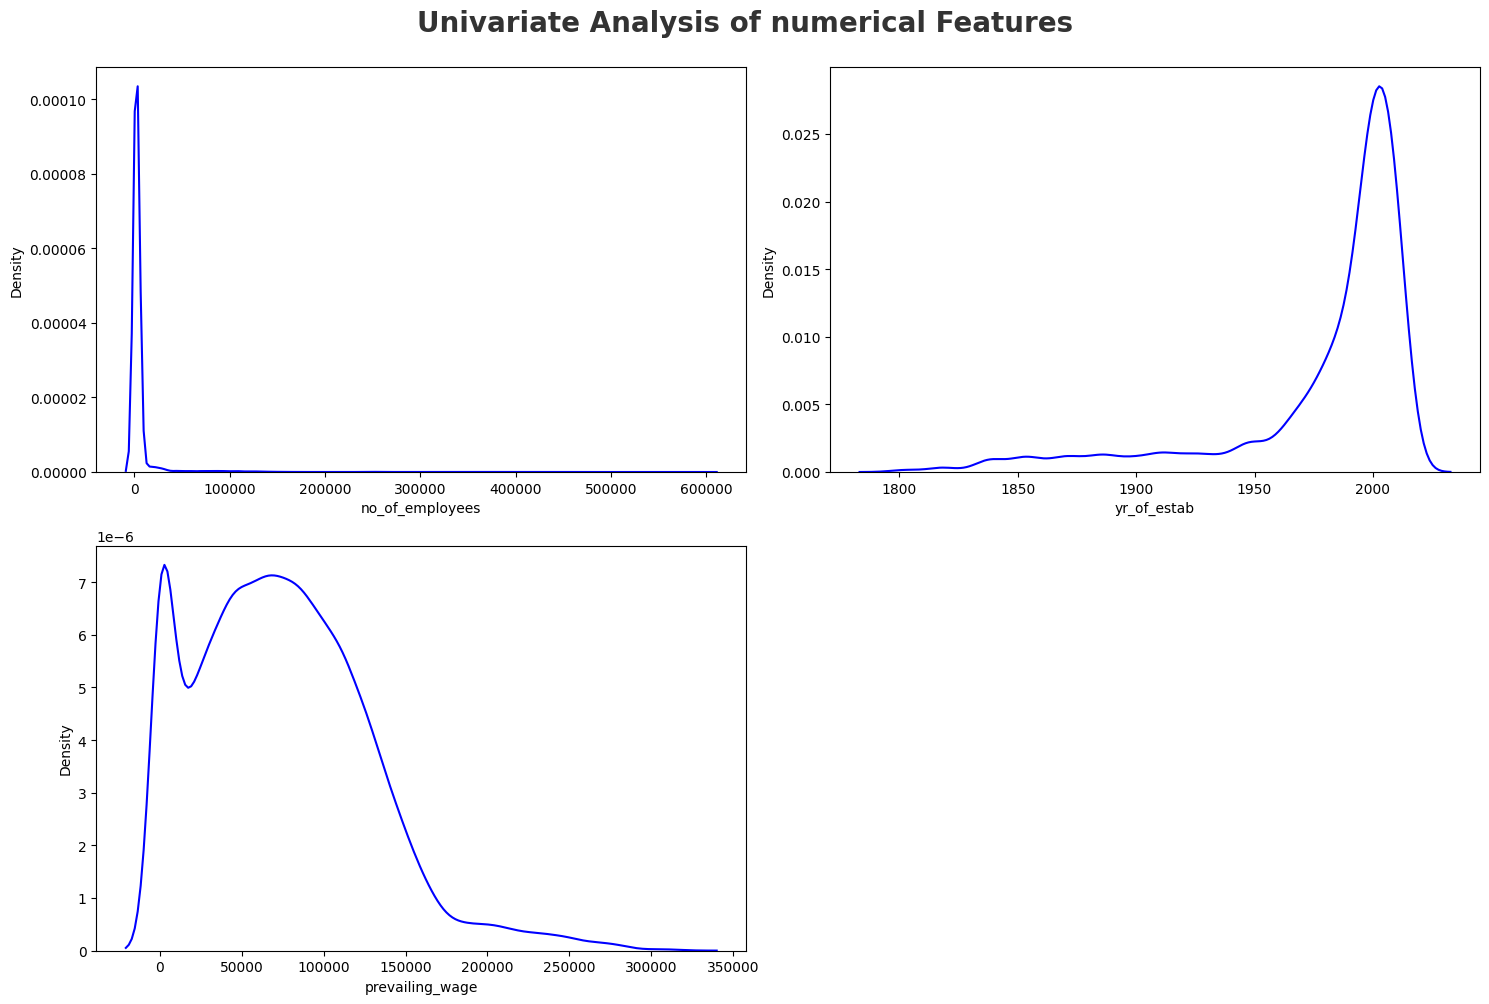

In [15]:
plt.figure(figsize=(15,10))
plt.suptitle("Univariate Analysis of numerical Features", fontsize=20,fontweight='bold',alpha=0.8,y=1.)

for i in range(0, len(numeric_features)):
    plt.subplot(2,2, i+1)
    sns.kdeplot(x=df[numeric_features[i]], color='blue')
    plt.xlabel(numeric_features[i])
plt.tight_layout()

In [13]:
import math

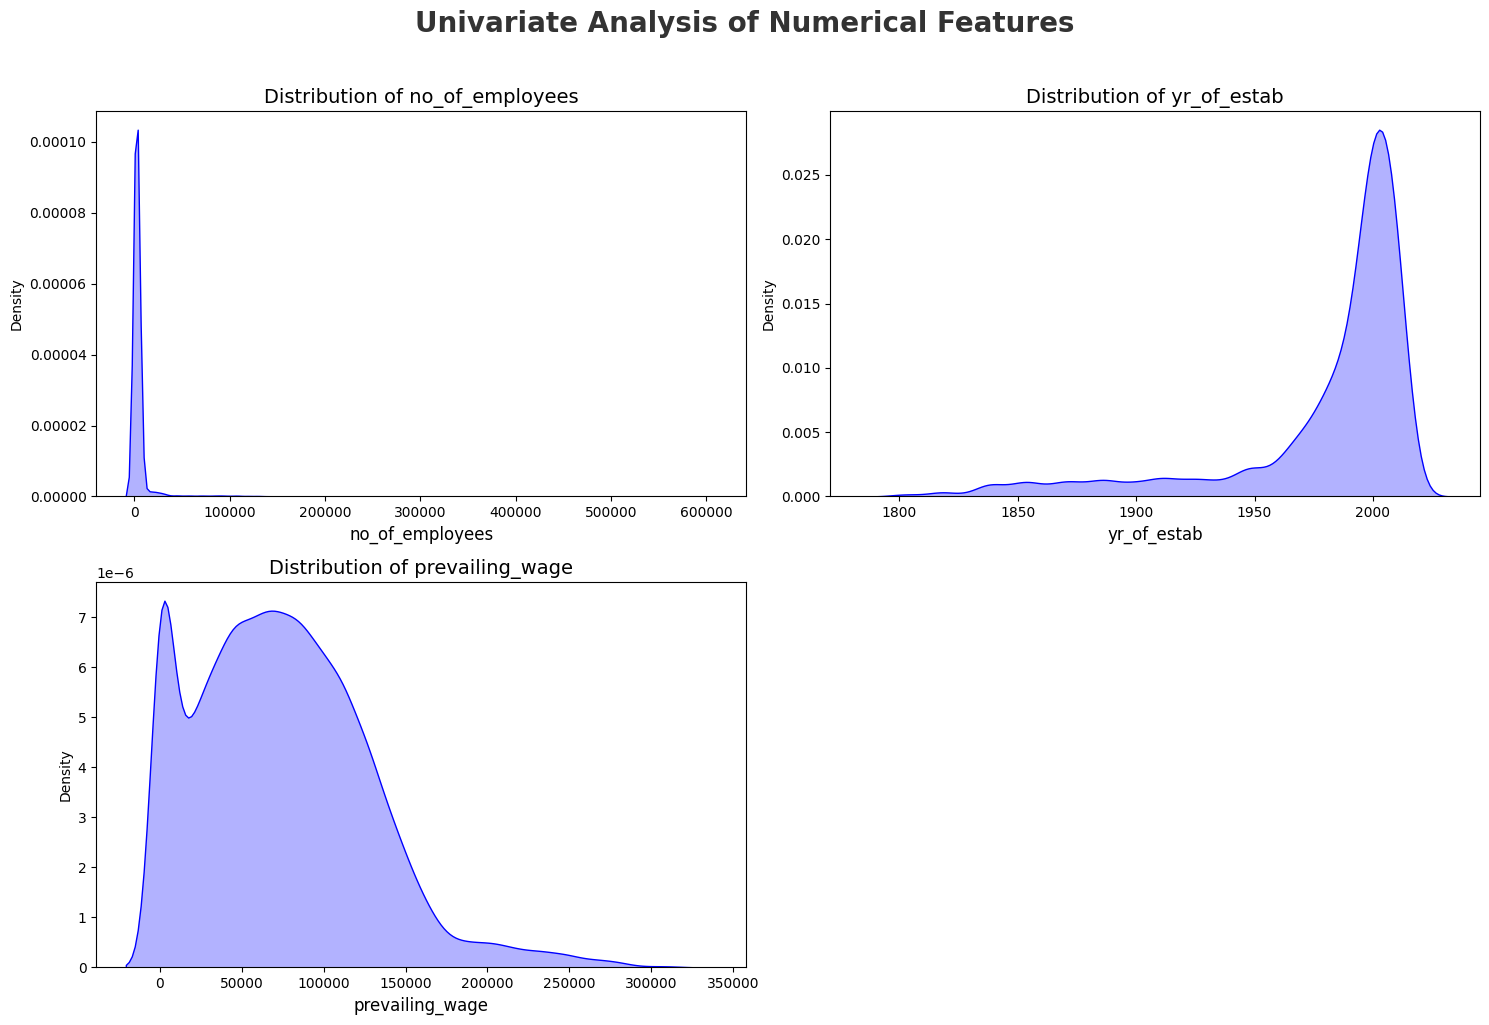

In [14]:
# Dynamically calculate rows and columns (2 columns layout)
n_features = len(numeric_features)
n_cols = 2
n_rows = math.ceil(n_features / n_cols)

plt.figure(figsize=(15, 5 * n_rows))
plt.suptitle("Univariate Analysis of Numerical Features", fontsize=20, fontweight='bold', alpha=0.8, y=1.02)

for i in range(n_features):
    plt.subplot(n_rows, n_cols, i + 1)
    
    # added fill=True for a cleaner density visualization
    sns.kdeplot(x=df[numeric_features[i]], color='blue', fill=True, alpha=0.3)
    
    plt.xlabel(numeric_features[i], fontsize=12)
    plt.title(f"Distribution of {numeric_features[i]}", fontsize=14)

# Call tight_layout once outside the loop at the end
plt.tight_layout()
plt.show()

## Insights
- no of employees column looks more skewed but it may be because of outliers
- Yr_of_estab is a discrete feature.
- privailing-wage is a right-skewed distribution


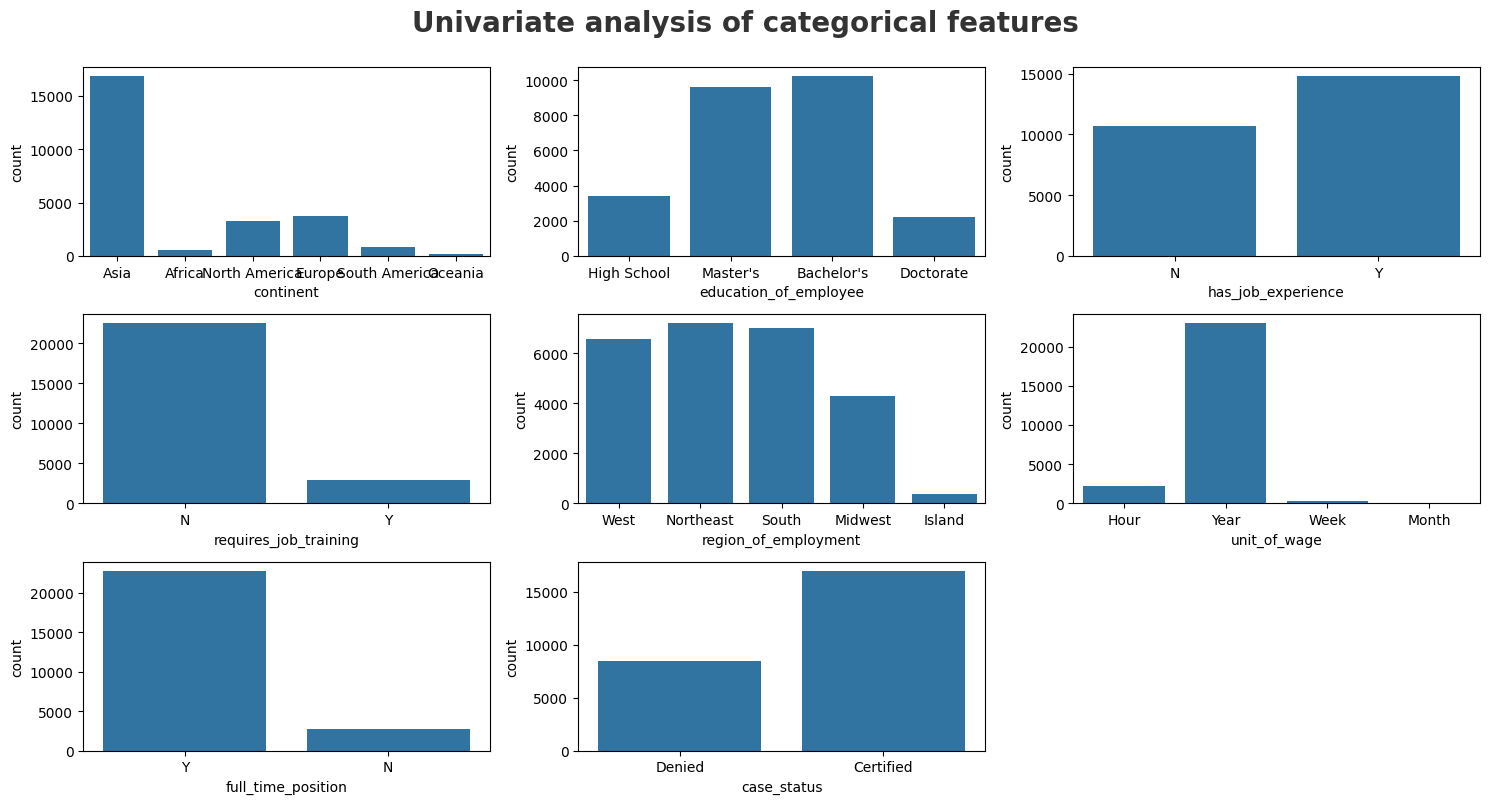

In [16]:
# Categorical columns
categorical_features.remove('case_id')
plt.figure(figsize=(15,8))
plt.suptitle("Univariate analysis of categorical features", fontsize=20, fontweight='bold', alpha=0.8,y=1.)

for i in range(0, len(categorical_features)):
    plt.subplot(3,3, i+1)
    sns.countplot(x=df[categorical_features[i]])
    plt.xlabel(categorical_features[i])

plt.tight_layout()

## Insights
- requires_job_training, unit_of_wage, full_time_position and continents columns have single category dominating
- In rest of the columns are balanced